In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import LogNorm, SymLogNorm
from galaxy_sidm.io import load_config, load_flat

cfg = load_config(None)
GAS = Path(cfg["paths"]["scratch_processed"]) / "gas_masses"
snap_of = {float(z): int(s) for s, z in cfg["snap_z"].items()}
models = ["CDM", "SIDM1", "vSIDM"]
colors = {"CDM": "orangered", "SIDM1": "turquoise", "vSIDM": "mediumslateblue"}
redshifts = [0.5, 1, 2, 3, 4, 5]
defs = ["all", "sfr", "sh03", "hdec_gas"]
def_colors = {"all": "k", "sfr": "turquoise", "sh03": "orangered", "hdec_gas": "mediumslateblue"}
show = [("CDM", 3, 19064), ("CDM", 3, 20669), ("CDM", 3, 9760)]
z_min = 0.1

In [2]:
data = {}
for model in models:
    for z in redshifts:
        data[(model, z)], _ = load_flat(GAS / f"gas_masses_{model}_{snap_of[z]:03d}.hdf5")
edges = data[(models[0], redshifts[0])]
zk = int(np.argmin(np.abs(edges["z_edges"] - z_min)))
z_bins = edges["z_edges"][zk:]
zc = np.sqrt(z_bins[1:] * z_bins[:-1])

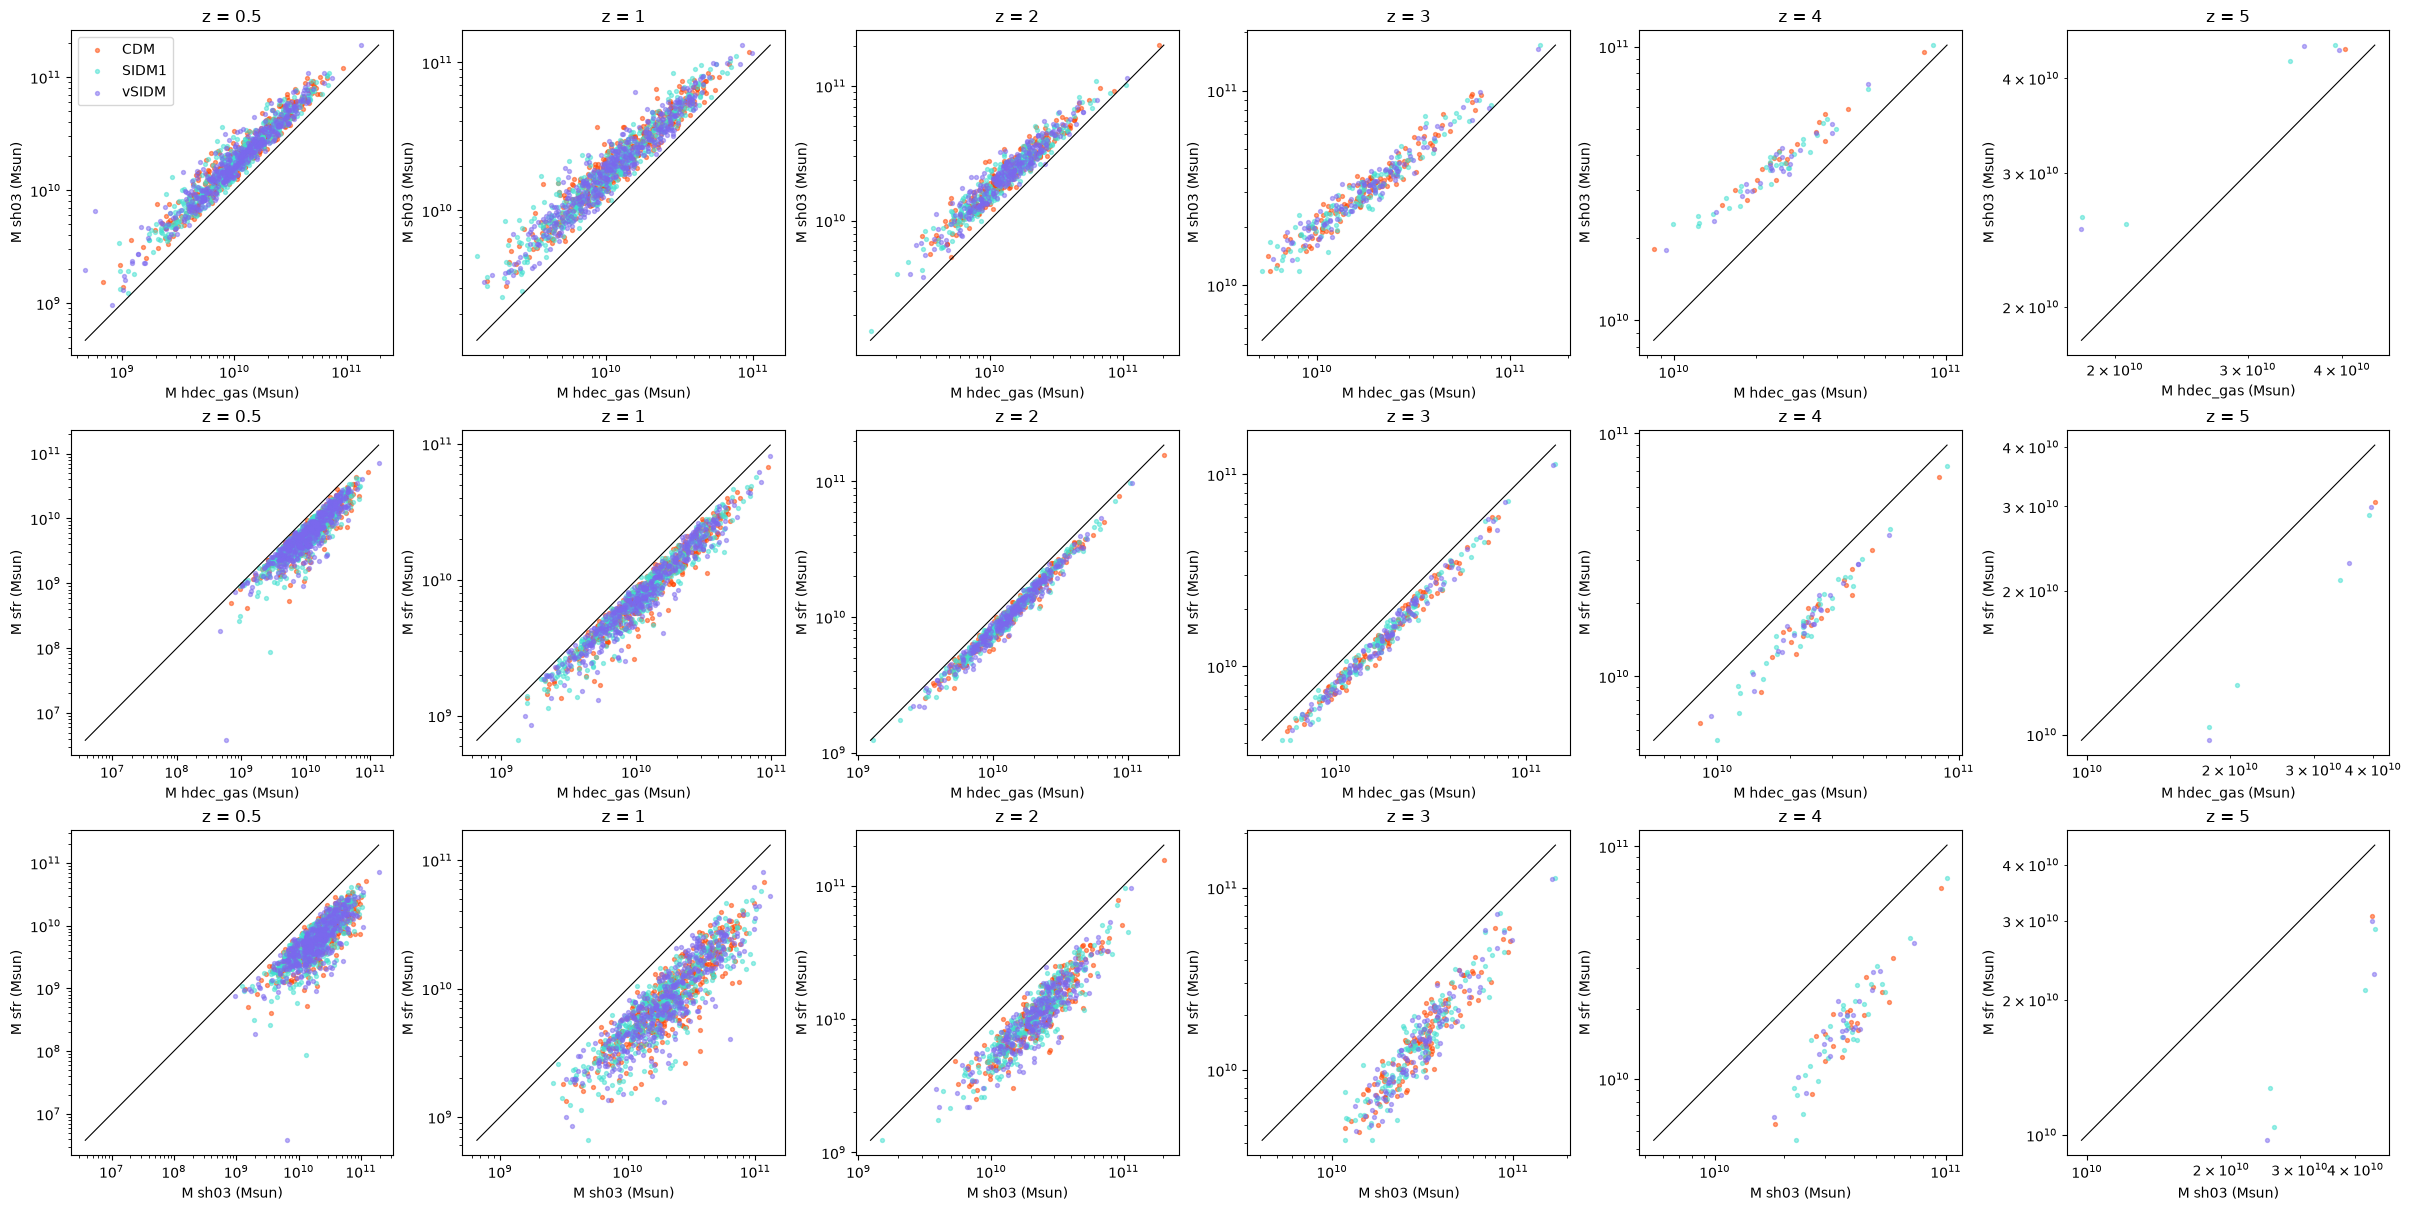

In [3]:
pairs = [("hdec_gas", "sh03"), ("hdec_gas", "sfr"), ("sh03", "sfr")]
fig, axes = plt.subplots(len(pairs), len(redshifts), figsize=(24, 12), constrained_layout=True)
for row, (x, y) in zip(axes, pairs):
    for ax, z in zip(row, redshifts):
        vals = []
        for model in models:
            a = data[(model, z)]
            ax.scatter(a[f"M_{x}"], a[f"M_{y}"], s=8, color=colors[model], alpha=0.5, label=model)
            vals += [a[f"M_{x}"], a[f"M_{y}"]]
        vals = np.concatenate(vals)
        vals = vals[vals > 0]
        ax.plot([vals.min(), vals.max()], [vals.min(), vals.max()], color="k", lw=0.8)
        ax.set_xscale("log", nonpositive="mask")
        ax.set_yscale("log", nonpositive="mask")
        ax.set_title(f"z = {z:g}")
        ax.set_xlabel(f"M {x} (Msun)")
        ax.set_ylabel(f"M {y} (Msun)")
axes[0, 0].legend()
plt.show()

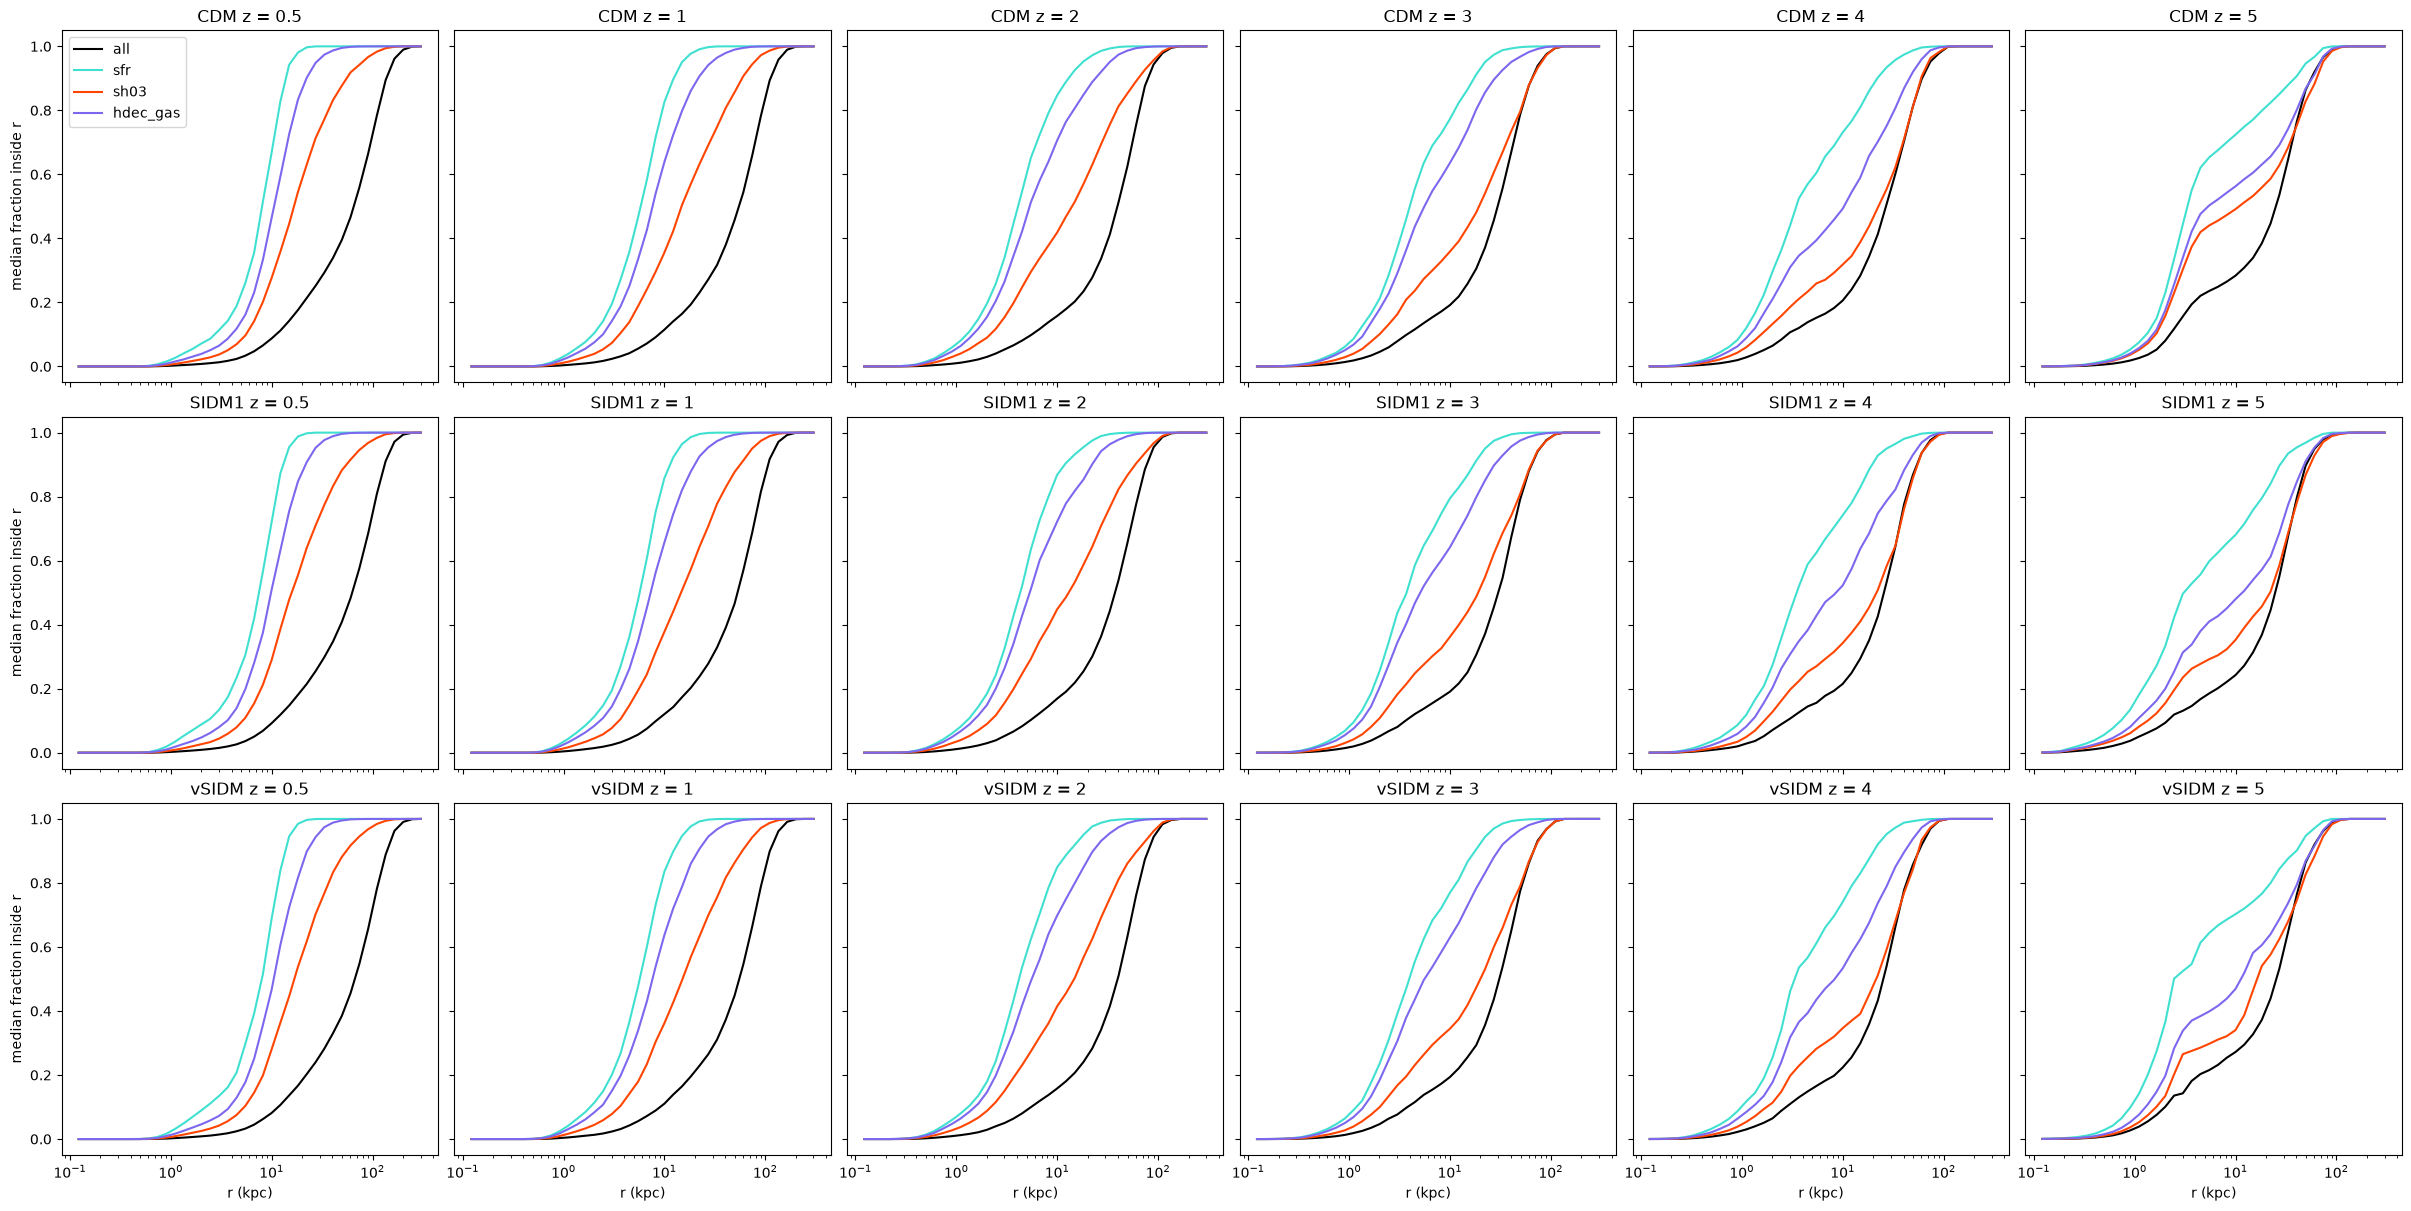

In [4]:
r = edges["r_edges"][1:]
fig, axes = plt.subplots(len(models), len(redshifts), figsize=(24, 12), sharex=True, sharey=True, constrained_layout=True)
for row, model in zip(axes, models):
    for ax, z in zip(row, redshifts):
        a = data[(model, z)]
        for d in defs:
            with np.errstate(invalid="ignore", divide="ignore"):
                cum = np.cumsum(a[f"prof_r_{d}"], axis=1) / a[f"M_{d}"][:, None]
            ax.plot(r, np.nanmedian(cum, axis=0), color=def_colors[d], label=d)
        ax.set_xscale("log")
        ax.set_title(f"{model} z = {z:g}")
for ax in axes[-1]:
    ax.set_xlabel("r (kpc)")
for ax in axes[:, 0]:
    ax.set_ylabel("median fraction inside r")
axes[0, 0].legend()
plt.show()

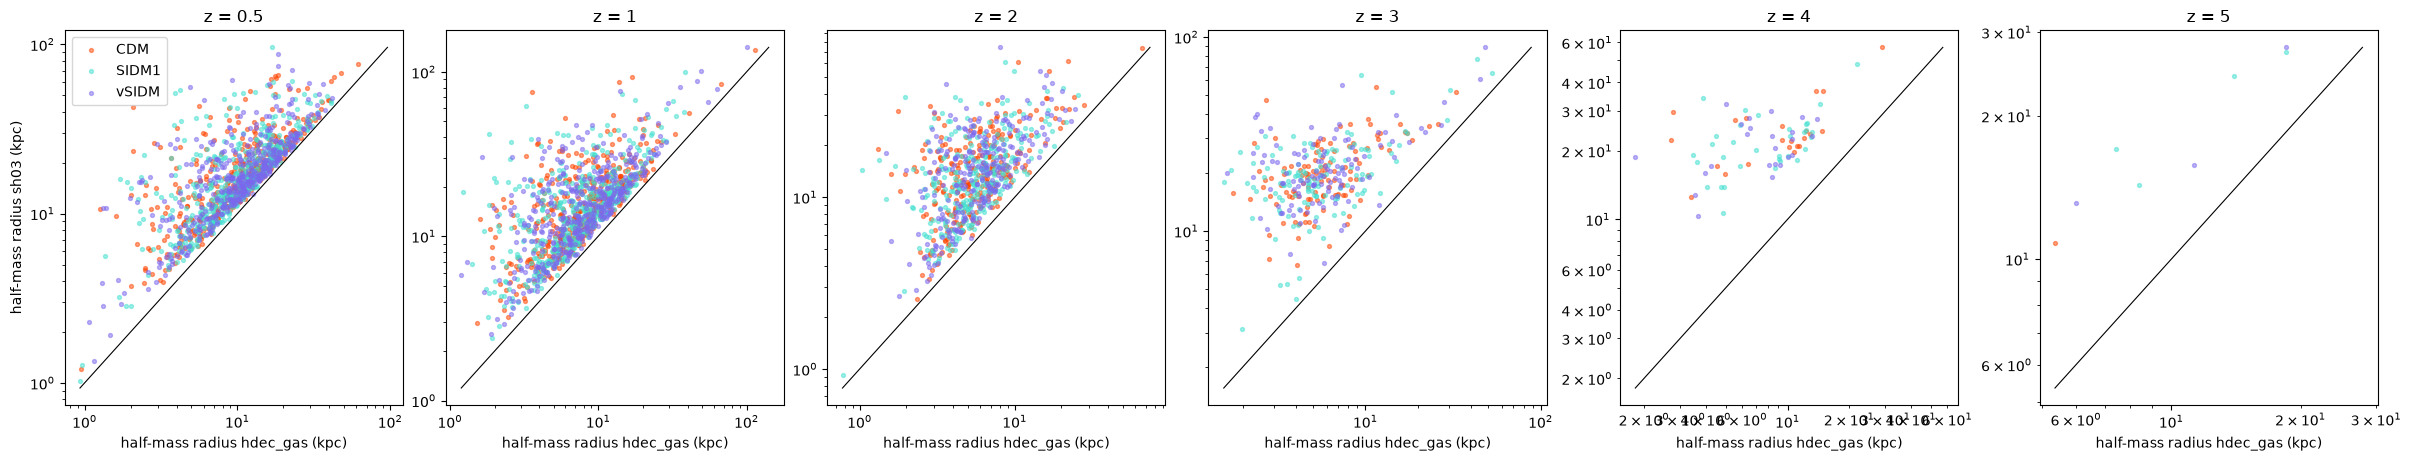

In [5]:
def mass_quantile(prof, total, bin_edges, q):
    cum = np.cumsum(prof, axis=1) / total[:, None]
    le = np.log10(bin_edges)
    out = np.full(len(total), np.nan)
    for i in range(len(total)):
        k = np.flatnonzero(cum[i] >= q)
        if len(k):
            k = k[0]
            below = cum[i, k - 1] if k else 0.0
            out[i] = 10 ** (le[k] + (q - below) / (cum[i, k] - below) * (le[k + 1] - le[k]))
    return out


fig, axes = plt.subplots(1, len(redshifts), figsize=(24, 4.5), constrained_layout=True)
for ax, z in zip(axes, redshifts):
    vals = []
    for model in models:
        a = data[(model, z)]
        x = mass_quantile(a["prof_r_hdec_gas"], a["M_hdec_gas"], edges["r_edges"], 0.5)
        y = mass_quantile(a["prof_r_sh03"], a["M_sh03"], edges["r_edges"], 0.5)
        ax.scatter(x, y, s=8, color=colors[model], alpha=0.5, label=model)
        vals += [x, y]
    vals = np.concatenate(vals)
    vals = vals[np.isfinite(vals)]
    ax.plot([vals.min(), vals.max()], [vals.min(), vals.max()], color="k", lw=0.8)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"z = {z:g}")
    ax.set_xlabel("half-mass radius hdec_gas (kpc)")
axes[0].set_ylabel("half-mass radius sh03 (kpc)")
axes[0].legend()
plt.show()

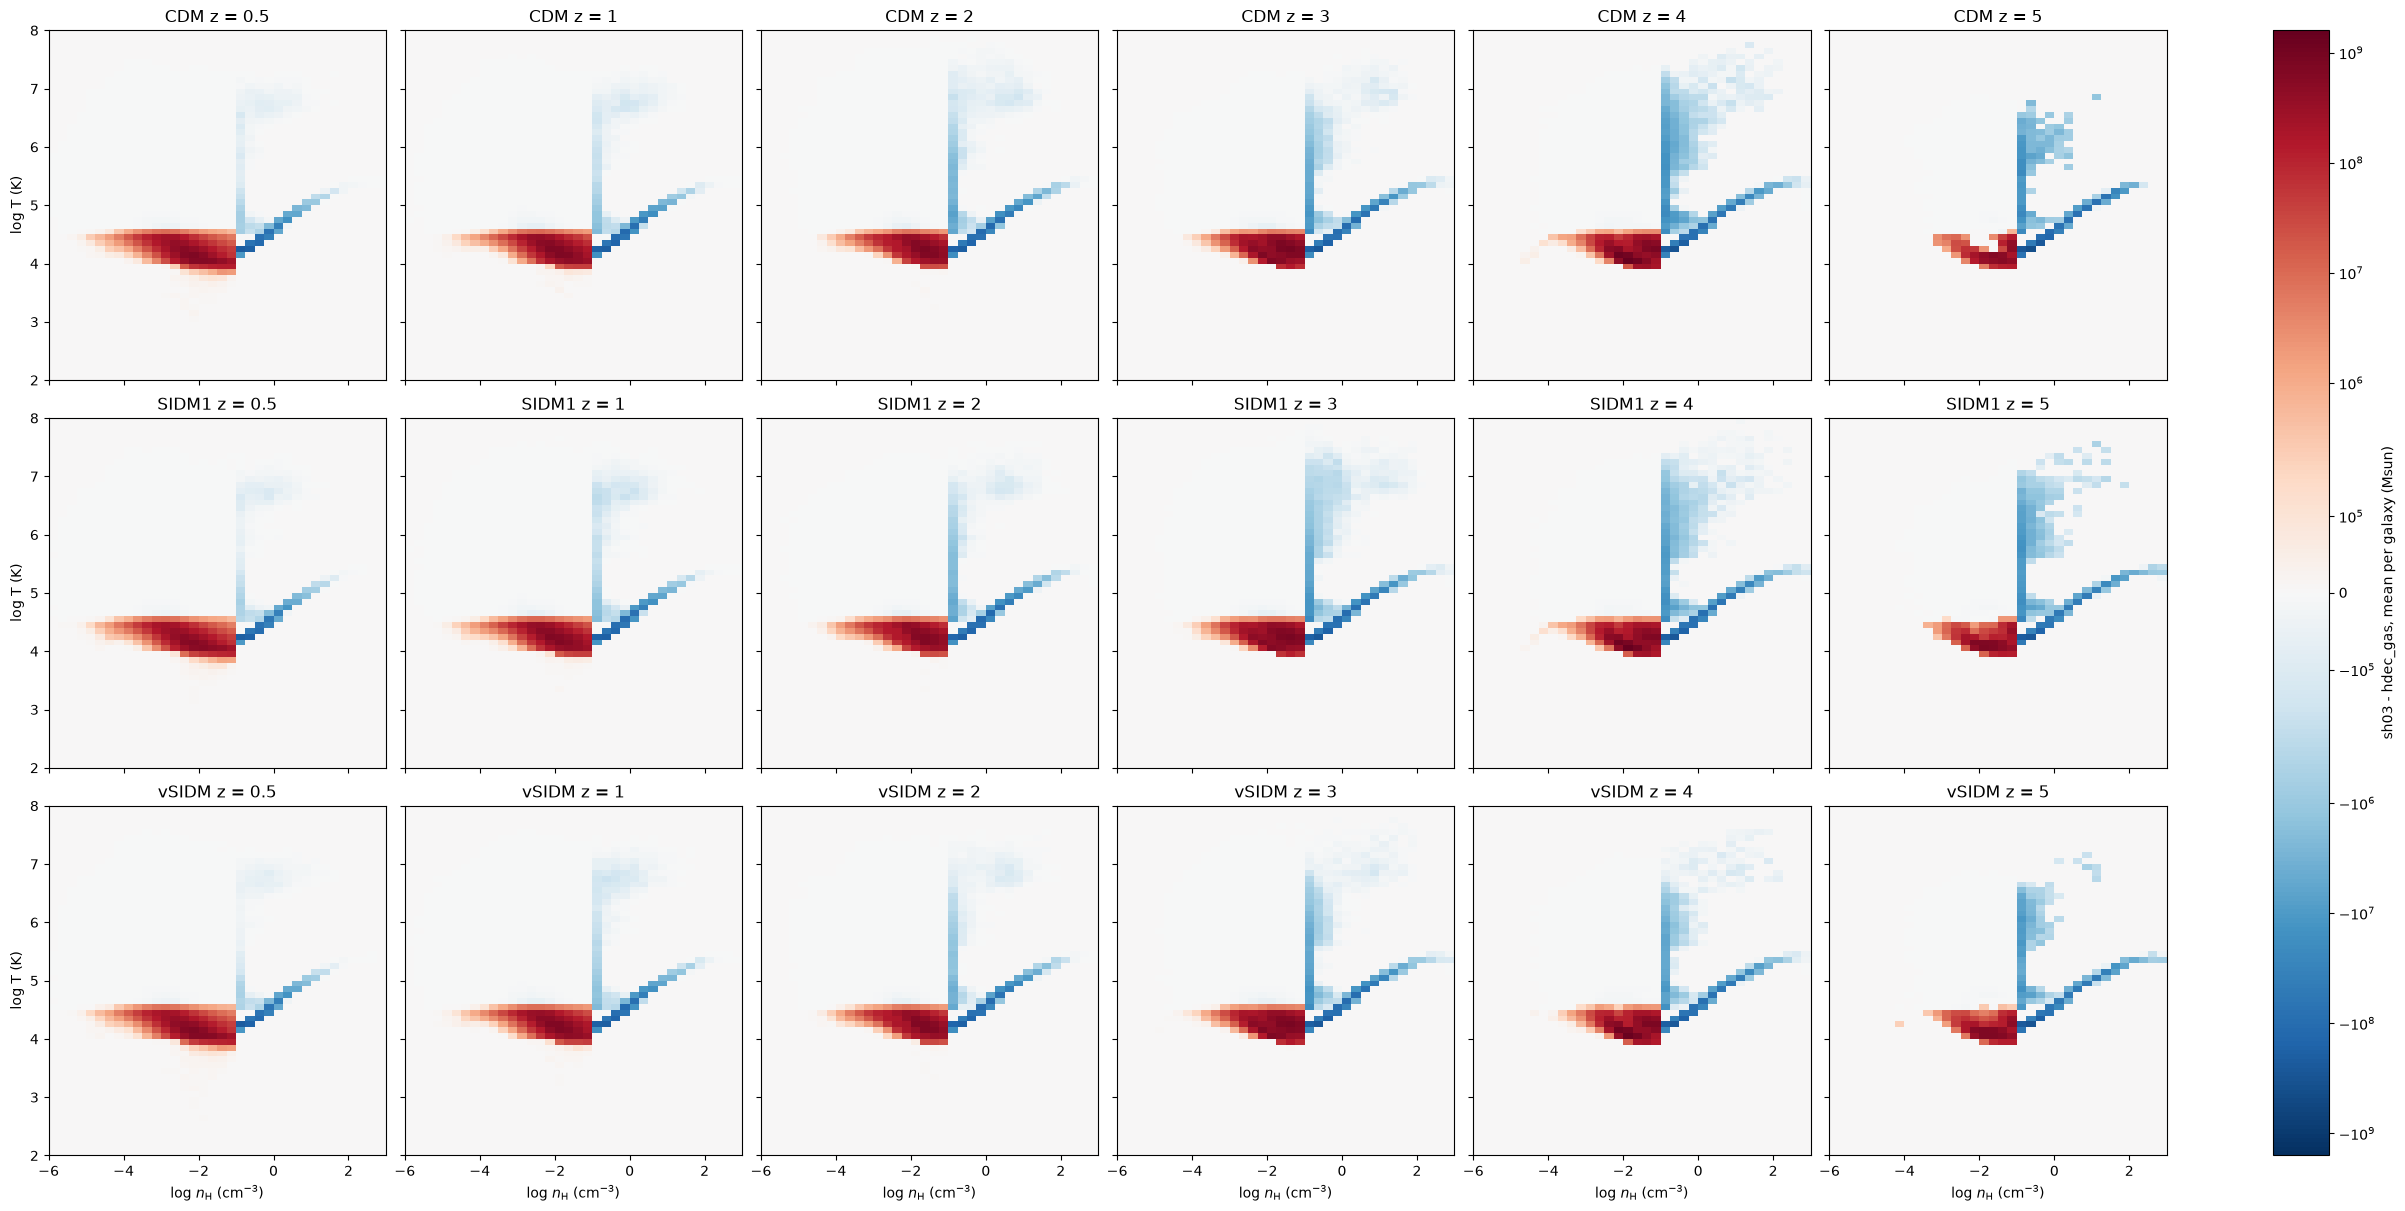

In [6]:
diff = {k: (a["map_nT_sh03"].astype(float) - a["map_nT_hdec_gas"]).mean(axis=0) for k, a in data.items()}
vmax = max(np.abs(d).max() for d in diff.values())
norm = SymLogNorm(linthresh=vmax * 1e-4, vmin=-vmax, vmax=vmax)
fig, axes = plt.subplots(len(models), len(redshifts), figsize=(24, 12), sharex=True, sharey=True, constrained_layout=True)
for row, model in zip(axes, models):
    for ax, z in zip(row, redshifts):
        im = ax.pcolormesh(edges["lognH_edges"], edges["logT_edges"], diff[(model, z)].T, cmap="RdBu_r", norm=norm)
        ax.set_title(f"{model} z = {z:g}")
for ax in axes[-1]:
    ax.set_xlabel(r"log $n_{\rm H}$ (cm$^{-3}$)")
for ax in axes[:, 0]:
    ax.set_ylabel("log T (K)")
fig.colorbar(im, ax=axes, label="sh03 - hdec_gas, mean per galaxy (Msun)")
plt.show()

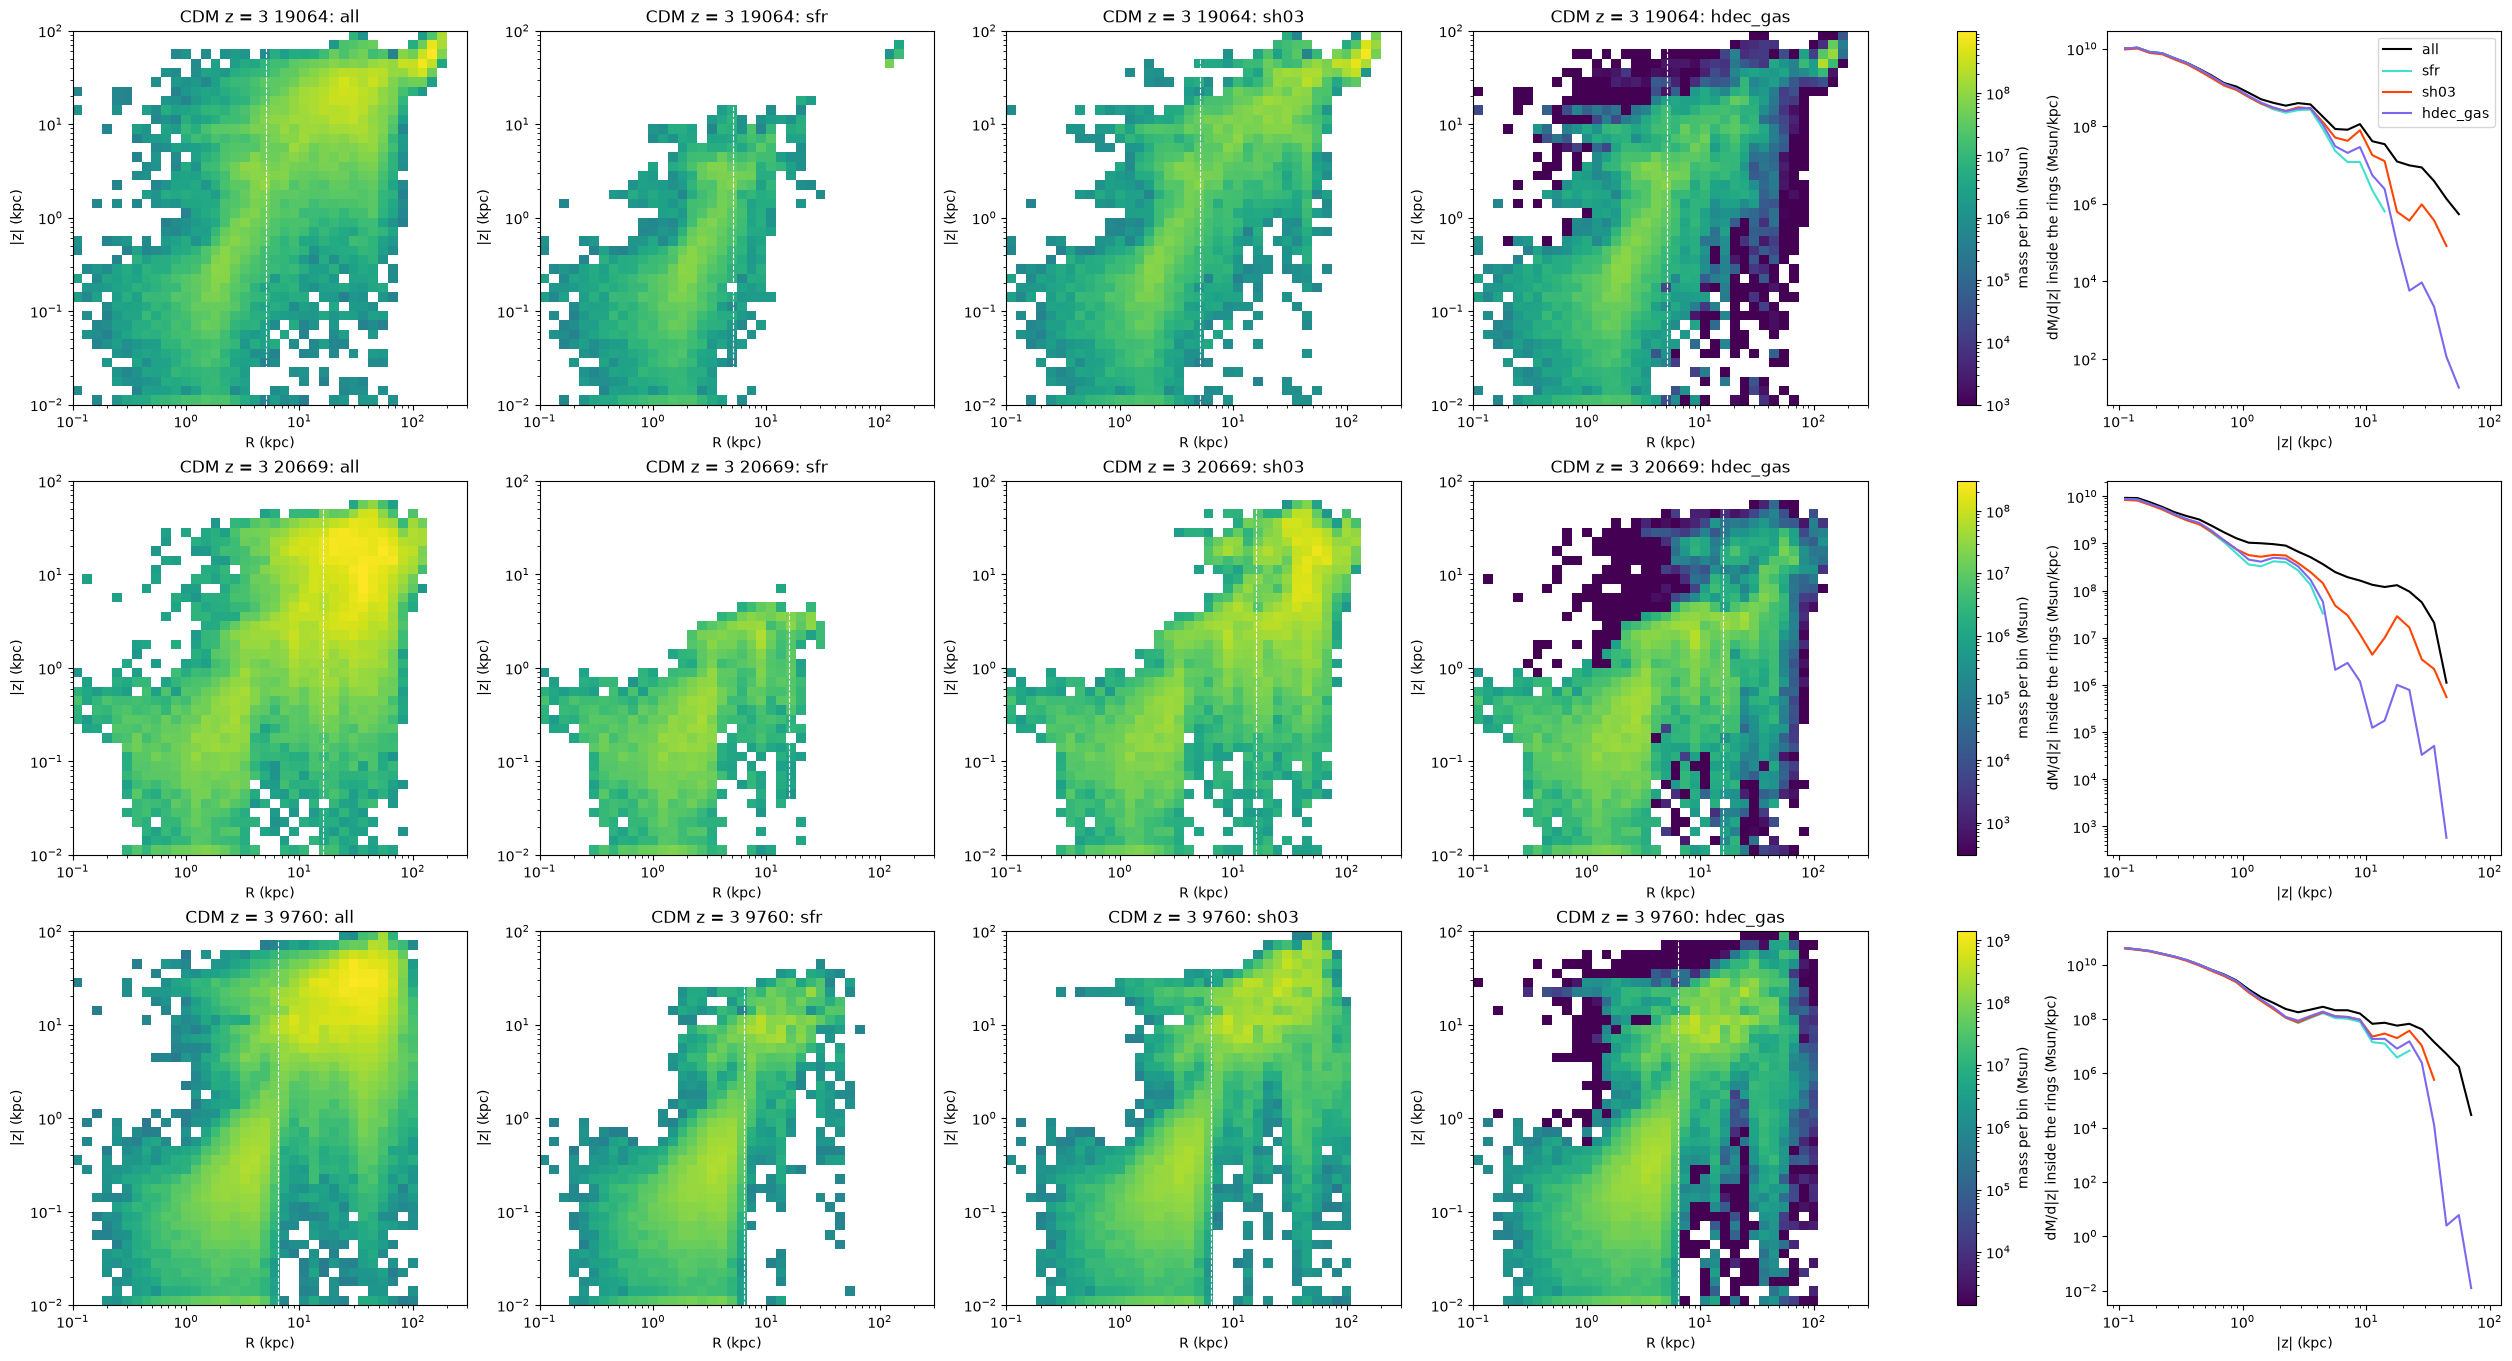

In [7]:
fig, axes = plt.subplots(len(show), len(defs) + 1, figsize=(5 * (len(defs) + 1), 4.5 * len(show)), constrained_layout=True)
for row, (model, z, sub) in zip(axes, show):
    a = data[(model, z)]
    i = np.flatnonzero(a["halo_ids"] == sub)
    if len(i) != 1:
        raise KeyError(f"{model} z{z} {sub} is not in the gas-mass file")
    i = i[0]
    vmax = max(a[f"map_Rz_{d}"][i].max() for d in defs)
    for ax, d in zip(row, defs):
        im = ax.pcolormesh(edges["R_edges"], edges["z_edges"], a[f"map_Rz_{d}"][i].T, norm=LogNorm(vmin=vmax * 1e-6, vmax=vmax))
        ax.axvline(a["R_rings_kpc"][i], color="w", lw=0.8, ls="--")
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_title(f"{model} z = {z:g} {sub}: {d}")
        ax.set_xlabel("R (kpc)")
        ax.set_ylabel("|z| (kpc)")
    fig.colorbar(im, ax=row[:-1], label="mass per bin (Msun)")
    inside = edges["R_edges"][1:] <= a["R_rings_kpc"][i]
    for d in defs:
        row[-1].plot(zc, a[f"map_Rz_{d}"][i][inside].sum(axis=0)[zk:] / np.diff(z_bins), color=def_colors[d], label=d)
    row[-1].set_xscale("log")
    row[-1].set_yscale("log", nonpositive="mask")
    row[-1].set_xlabel("|z| (kpc)")
    row[-1].set_ylabel("dM/d|z| inside the rings (Msun/kpc)")
axes[0, -1].legend()
plt.show()

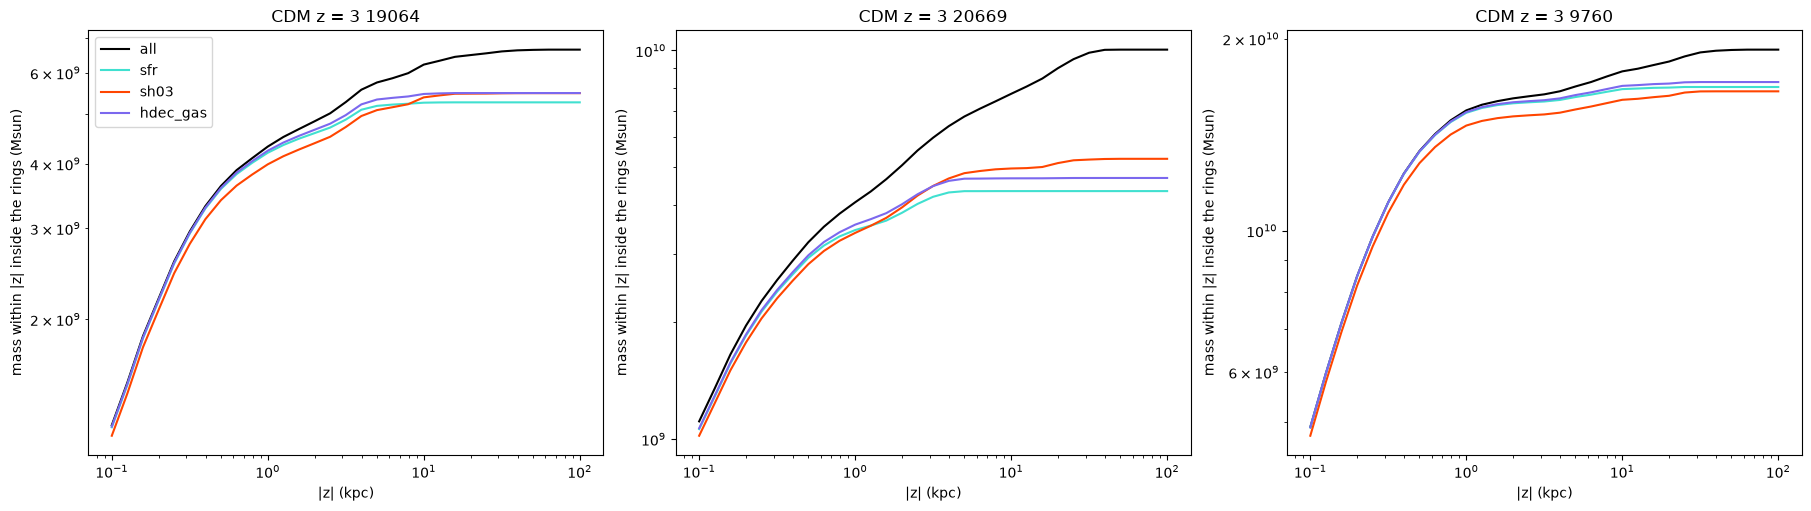

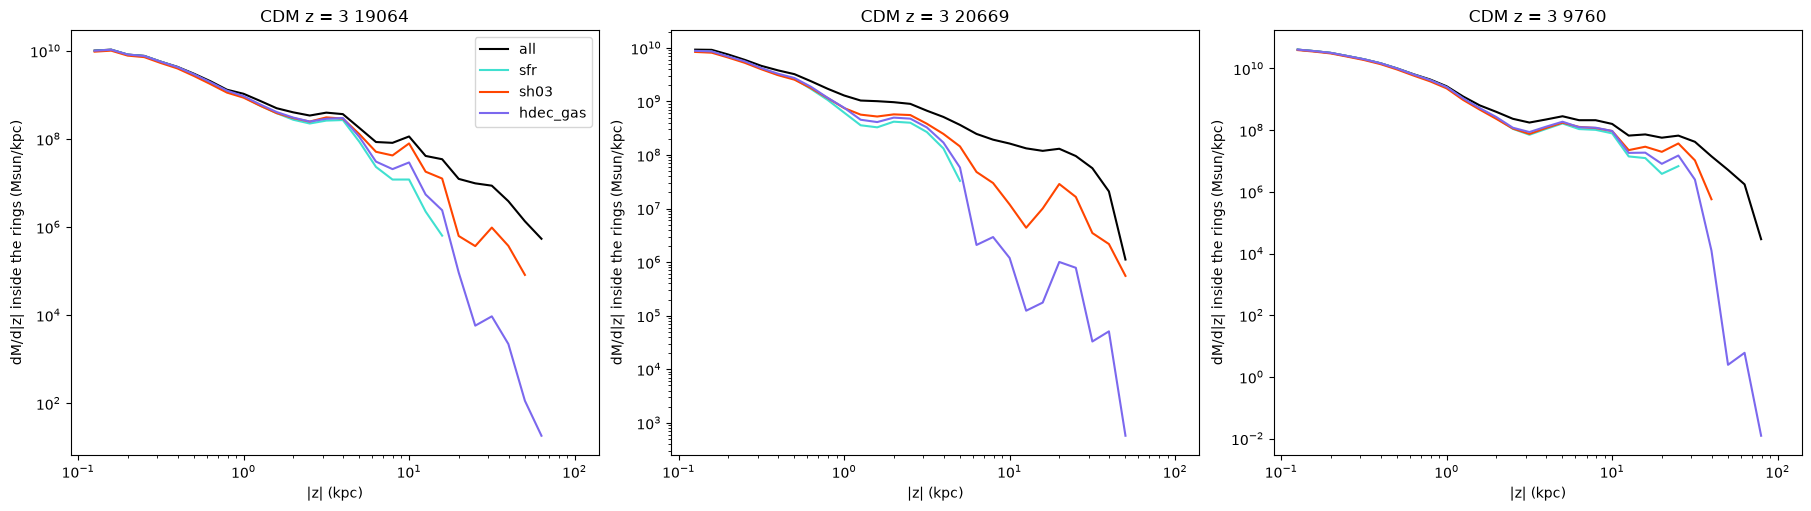

In [8]:
show = [("CDM", 3, 19064), ("CDM", 3, 20669), ("CDM", 3, 9760)]

fig, axes = plt.subplots(1, len(show), figsize=(6 * len(show), 5), constrained_layout=True, squeeze=False)
for ax, (model, z, sub) in zip(axes[0], show):
    a = data[(model, z)]
    i = np.flatnonzero(a["halo_ids"] == sub)
    if len(i) != 1:
        raise KeyError(f"{model} z{z} {sub} is not in the gas-mass file")
    i = i[0]
    inside = edges["R_edges"][1:] <= a["R_rings_kpc"][i]
    for d in defs:
        ax.plot(z_bins, np.cumsum(a[f"map_Rz_{d}"][i][inside].sum(axis=0))[zk - 1:], color=def_colors[d], label=d)
    ax.set_xscale("log")
    ax.set_yscale("log", nonpositive="mask")
    ax.set_title(f"{model} z = {z:g} {sub}")
    ax.set_xlabel("|z| (kpc)")
    ax.set_ylabel("mass within |z| inside the rings (Msun)")
axes[0, 0].legend()
plt.show()

fig, axes = plt.subplots(1, len(show), figsize=(6 * len(show), 5), constrained_layout=True, squeeze=False)
for ax, (model, z, sub) in zip(axes[0], show):
    a = data[(model, z)]
    i = np.flatnonzero(a["halo_ids"] == sub)
    if len(i) != 1:
        raise KeyError(f"{model} z{z} {sub} is not in the gas-mass file")
    i = i[0]
    inside = edges["R_edges"][1:] <= a["R_rings_kpc"][i]
    for d in defs:
        ax.plot(z_bins[1:], a[f"map_Rz_{d}"][i][inside].sum(axis=0)[zk:] / np.diff(z_bins), color=def_colors[d], label=d)
    ax.set_xscale("log")
    ax.set_yscale("log", nonpositive="mask")
    ax.set_title(f"{model} z = {z:g} {sub}")
    ax.set_xlabel("|z| (kpc)")
    ax.set_ylabel("dM/d|z| inside the rings (Msun/kpc)")
axes[0, 0].legend()
plt.show()

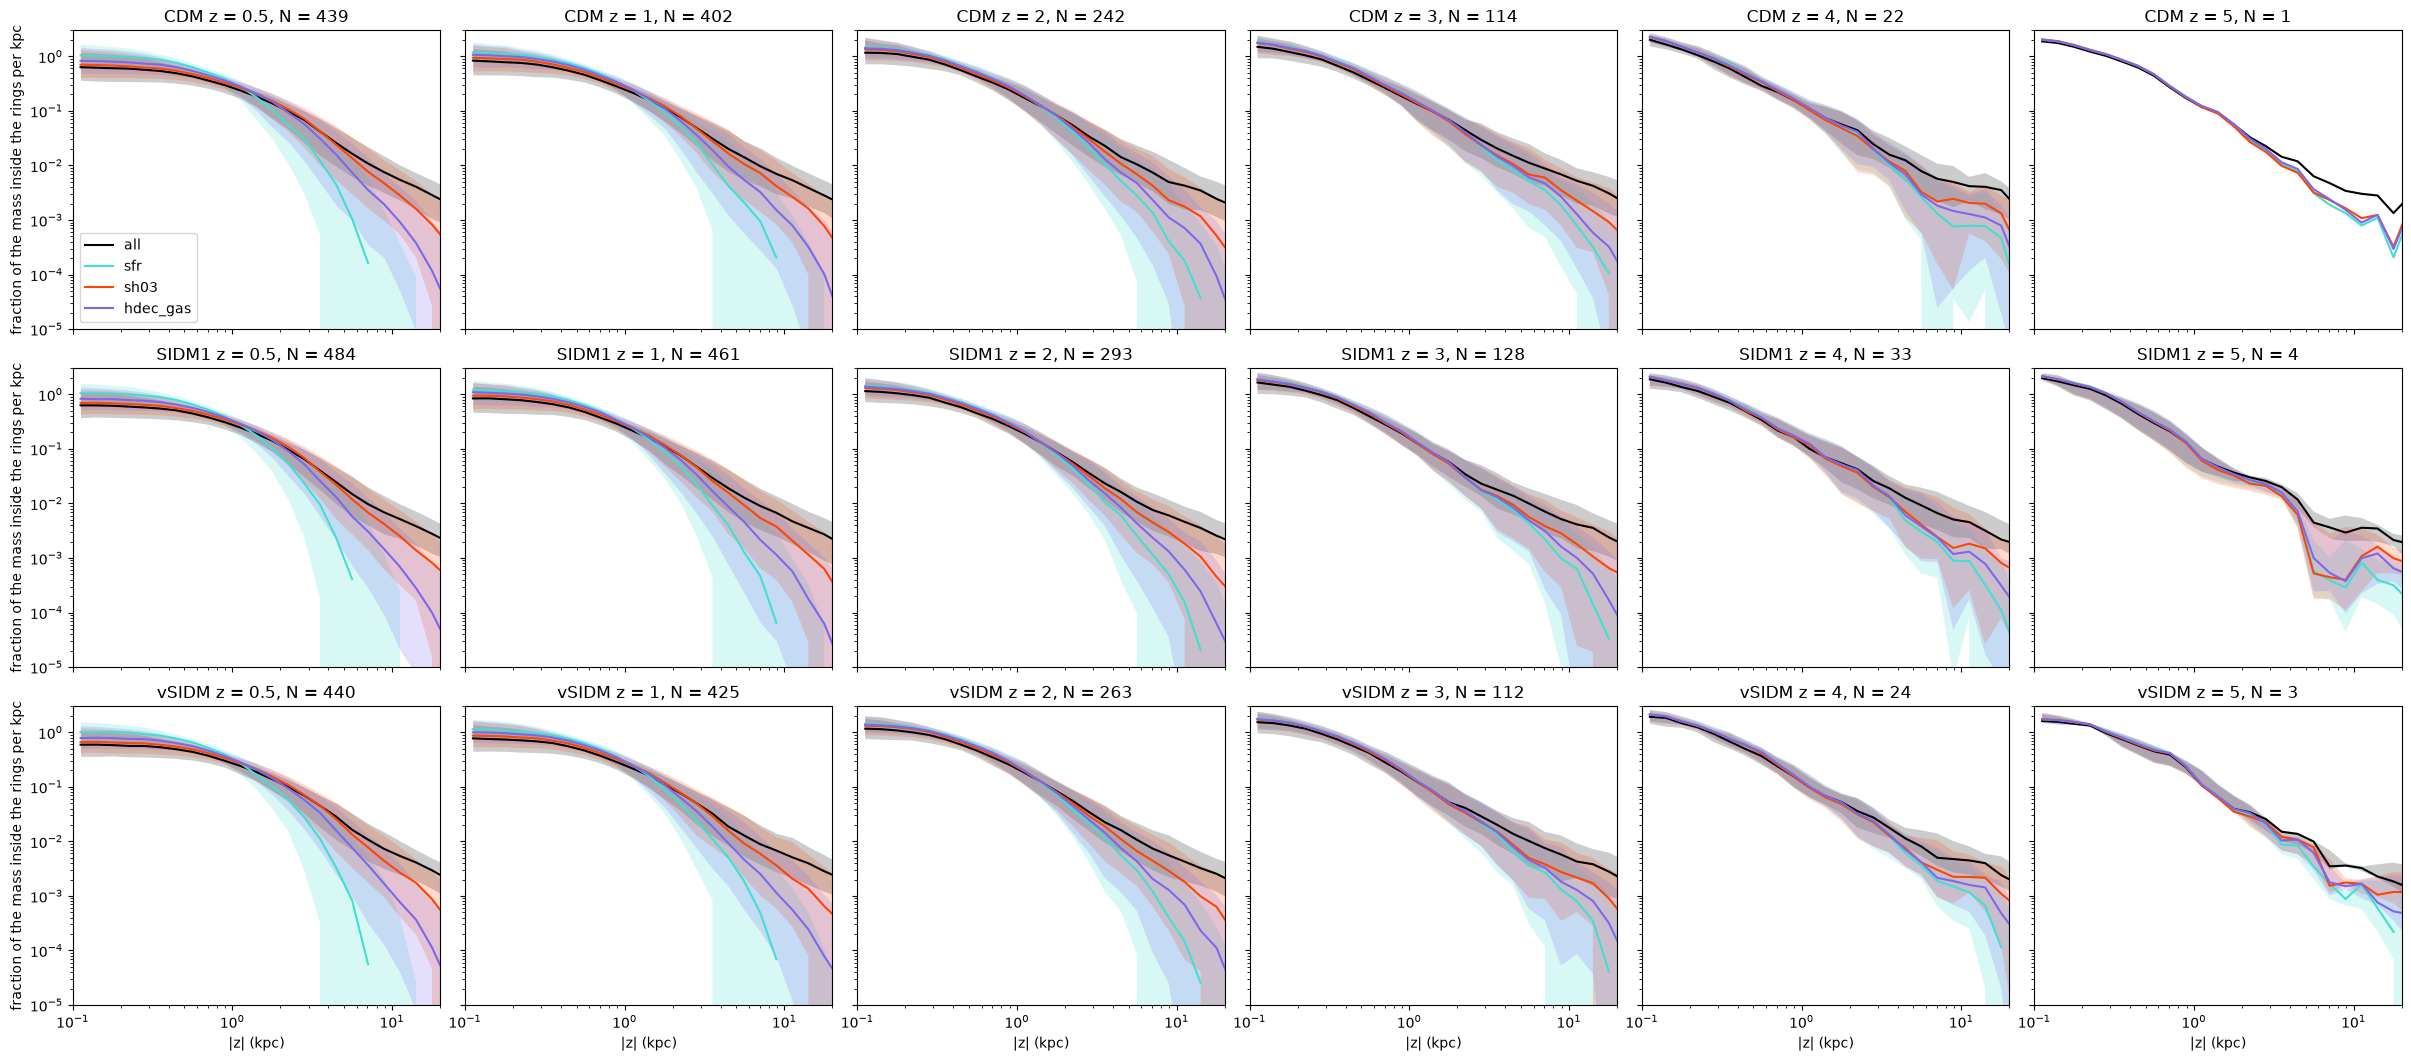

In [9]:
fig, axes = plt.subplots(len(models), len(redshifts), figsize=(4 * len(redshifts), 3.5 * len(models)), sharex=True, sharey=True, constrained_layout=True)
for row, model in zip(axes, models):
    for ax, z in zip(row, redshifts):
        a = data[(model, z)]
        inside = edges["R_edges"][1:][None, :] <= a["R_rings_kpc"][:, None]
        for d in defs:
            prof = (a[f"map_Rz_{d}"] * inside[:, :, None]).sum(axis=1)
            total = prof.sum(axis=1)
            ok = total > 0
            if (~ok).any():
                print(f"{model} z = {z:g} {d}: {(~ok).sum()} of {len(ok)} galaxies have no mass inside the rings, left out")
            if not ok.any():
                continue
            frac = prof[ok][:, zk:] / total[ok, None] / np.diff(z_bins)
            p16, p50, p84 = np.percentile(frac, [16, 50, 84], axis=0)
            ax.plot(zc, np.where(p50 > 0, p50, np.nan), color=def_colors[d], label=d)
            ax.fill_between(zc, p16, p84, color=def_colors[d], alpha=0.2, lw=0)
        ax.set_xscale("log")
        ax.set_xlim(0.1, 20)
        ax.set_ylim(1e-5, 3)
        ax.set_yscale("log", nonpositive="clip")
        ax.set_title(f"{model} z = {z:g}, N = {len(a['halo_ids'])}")
for ax in axes[-1]:
    ax.set_xlabel("|z| (kpc)")
for ax in axes[:, 0]:
    ax.set_ylabel("fraction of the mass inside the rings per kpc")
axes[0, 0].legend()
plt.show()

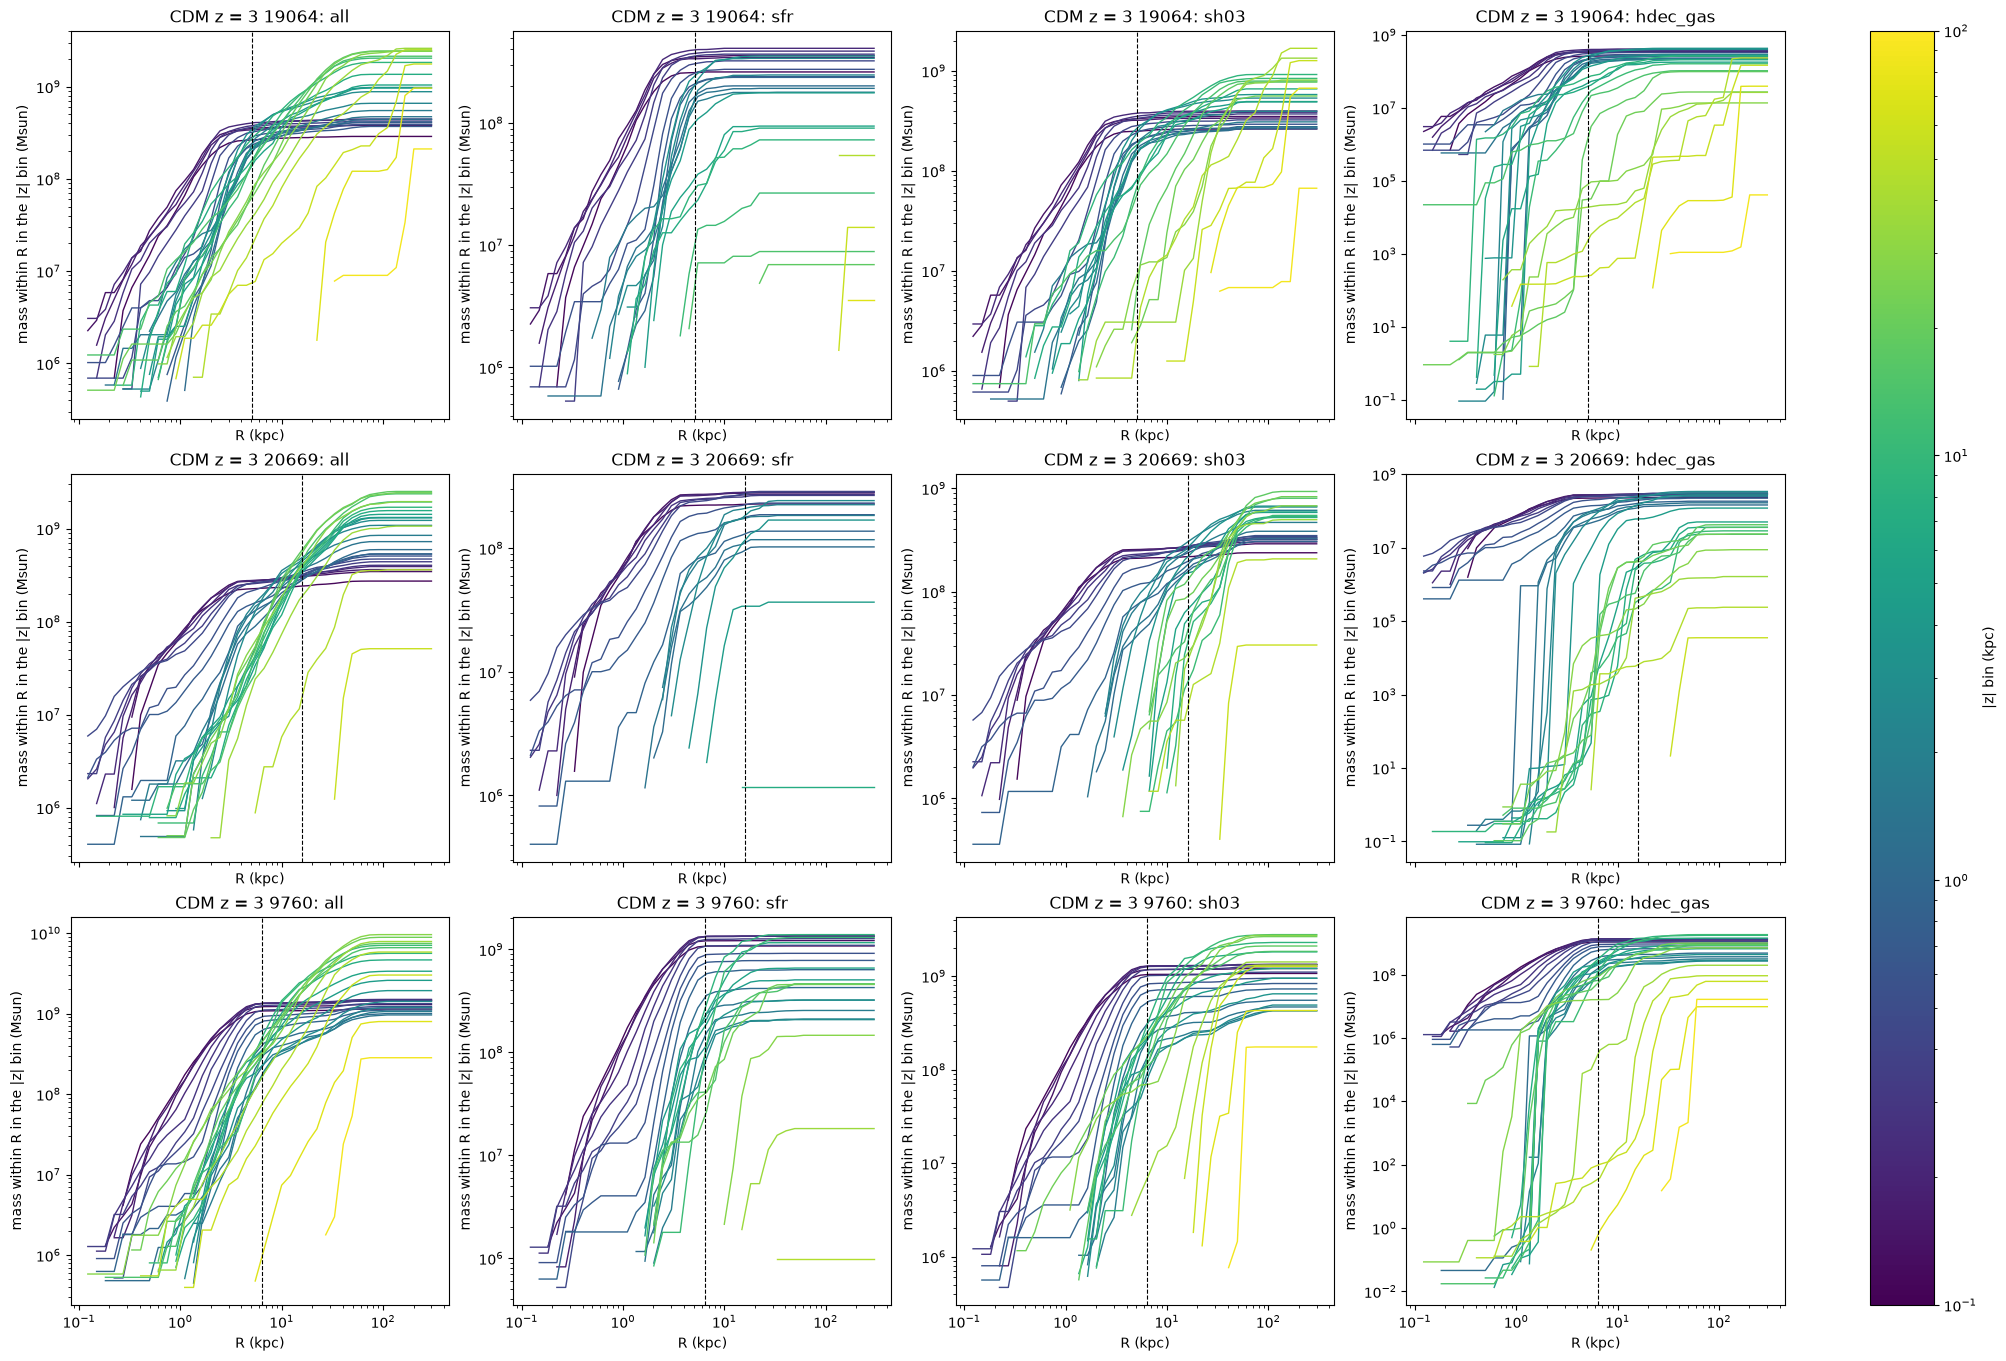

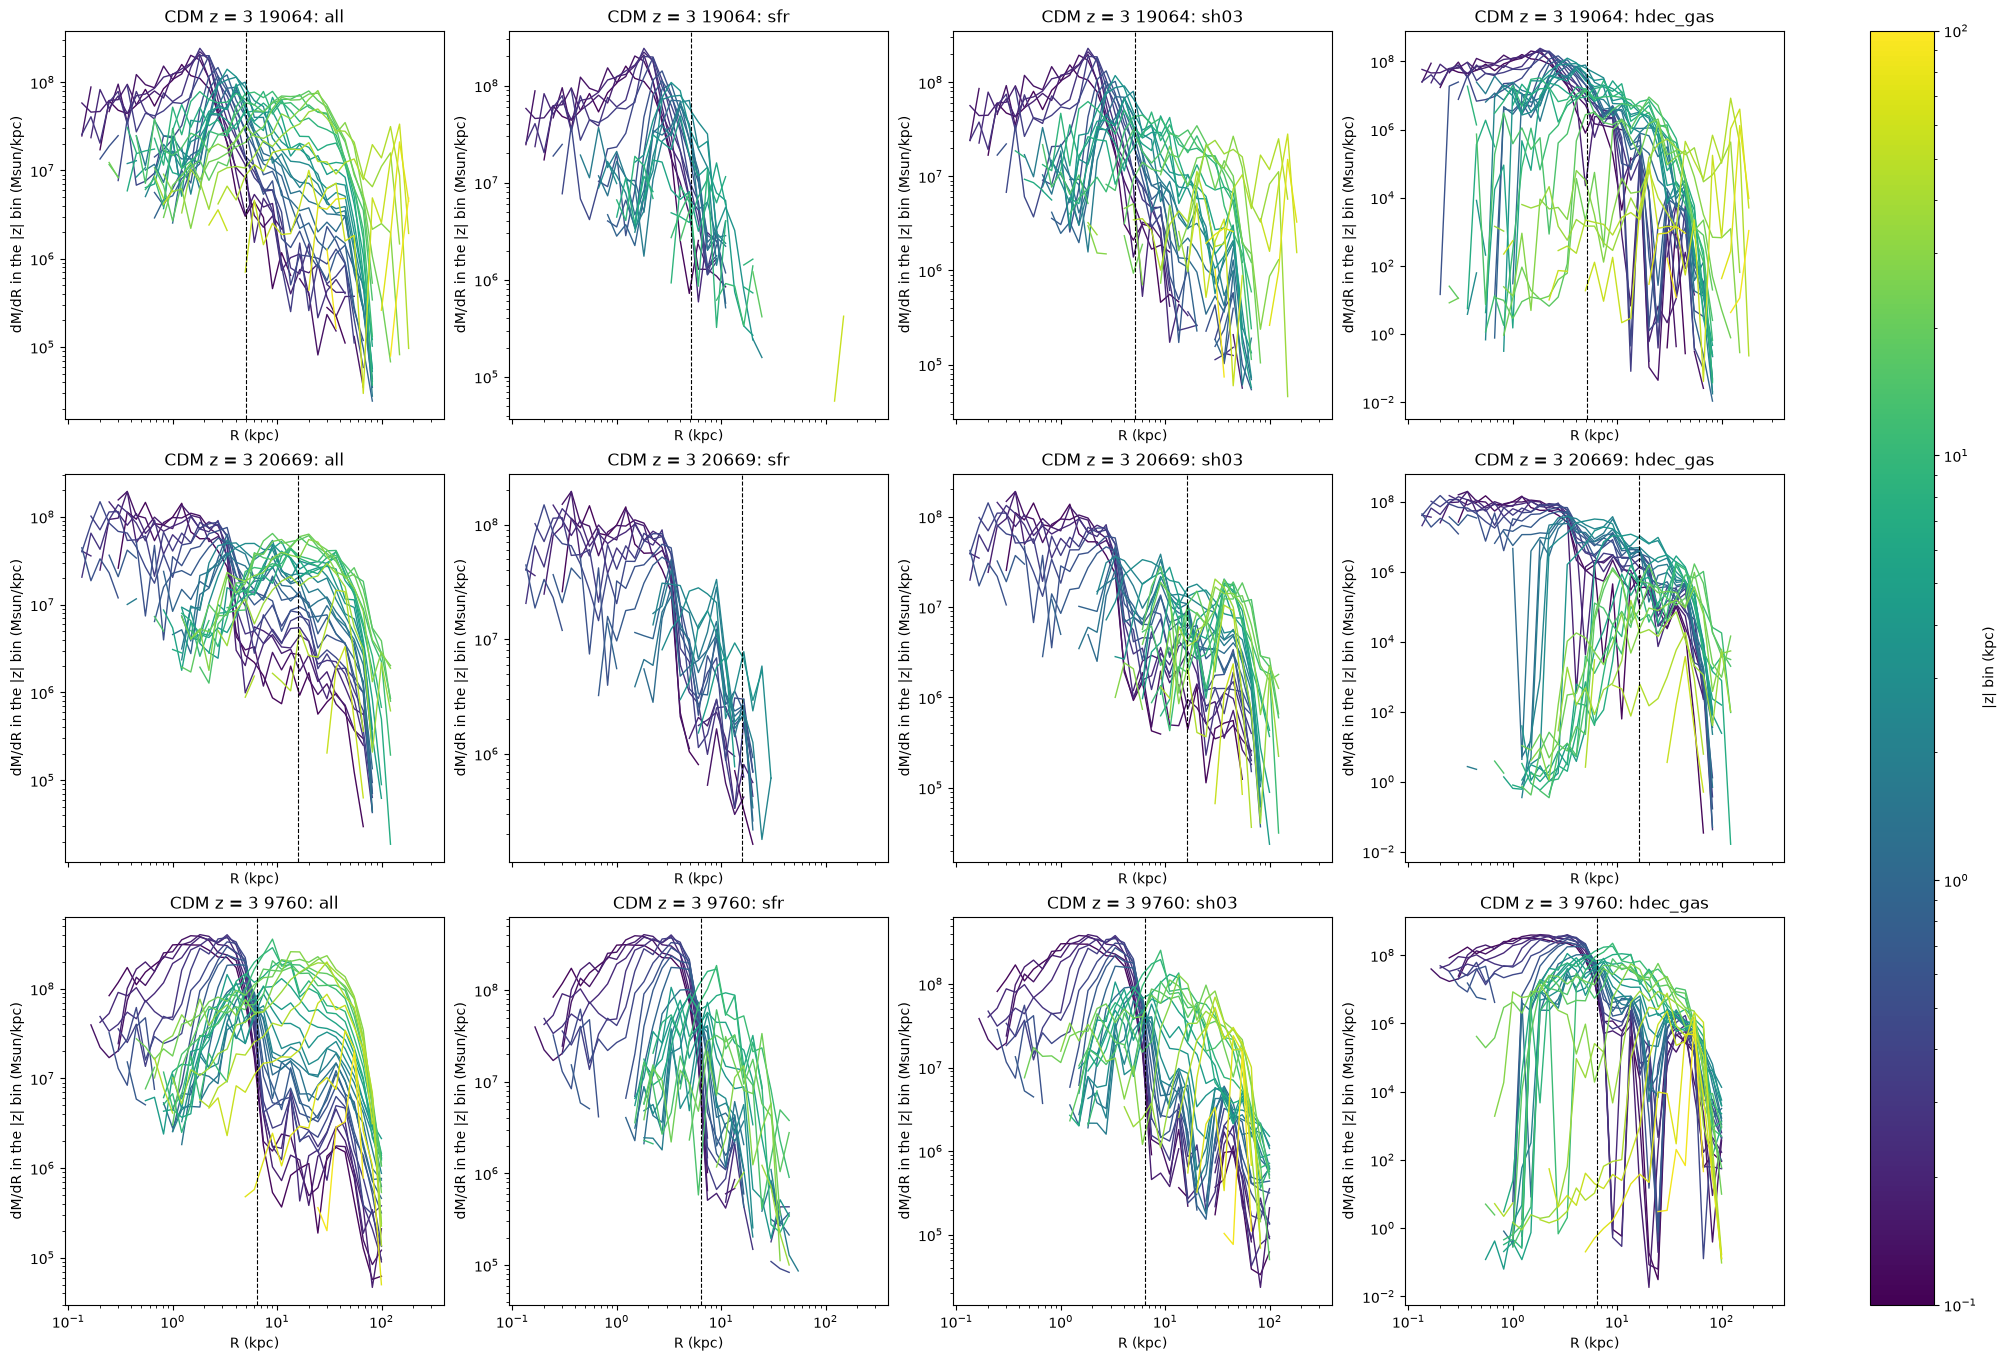

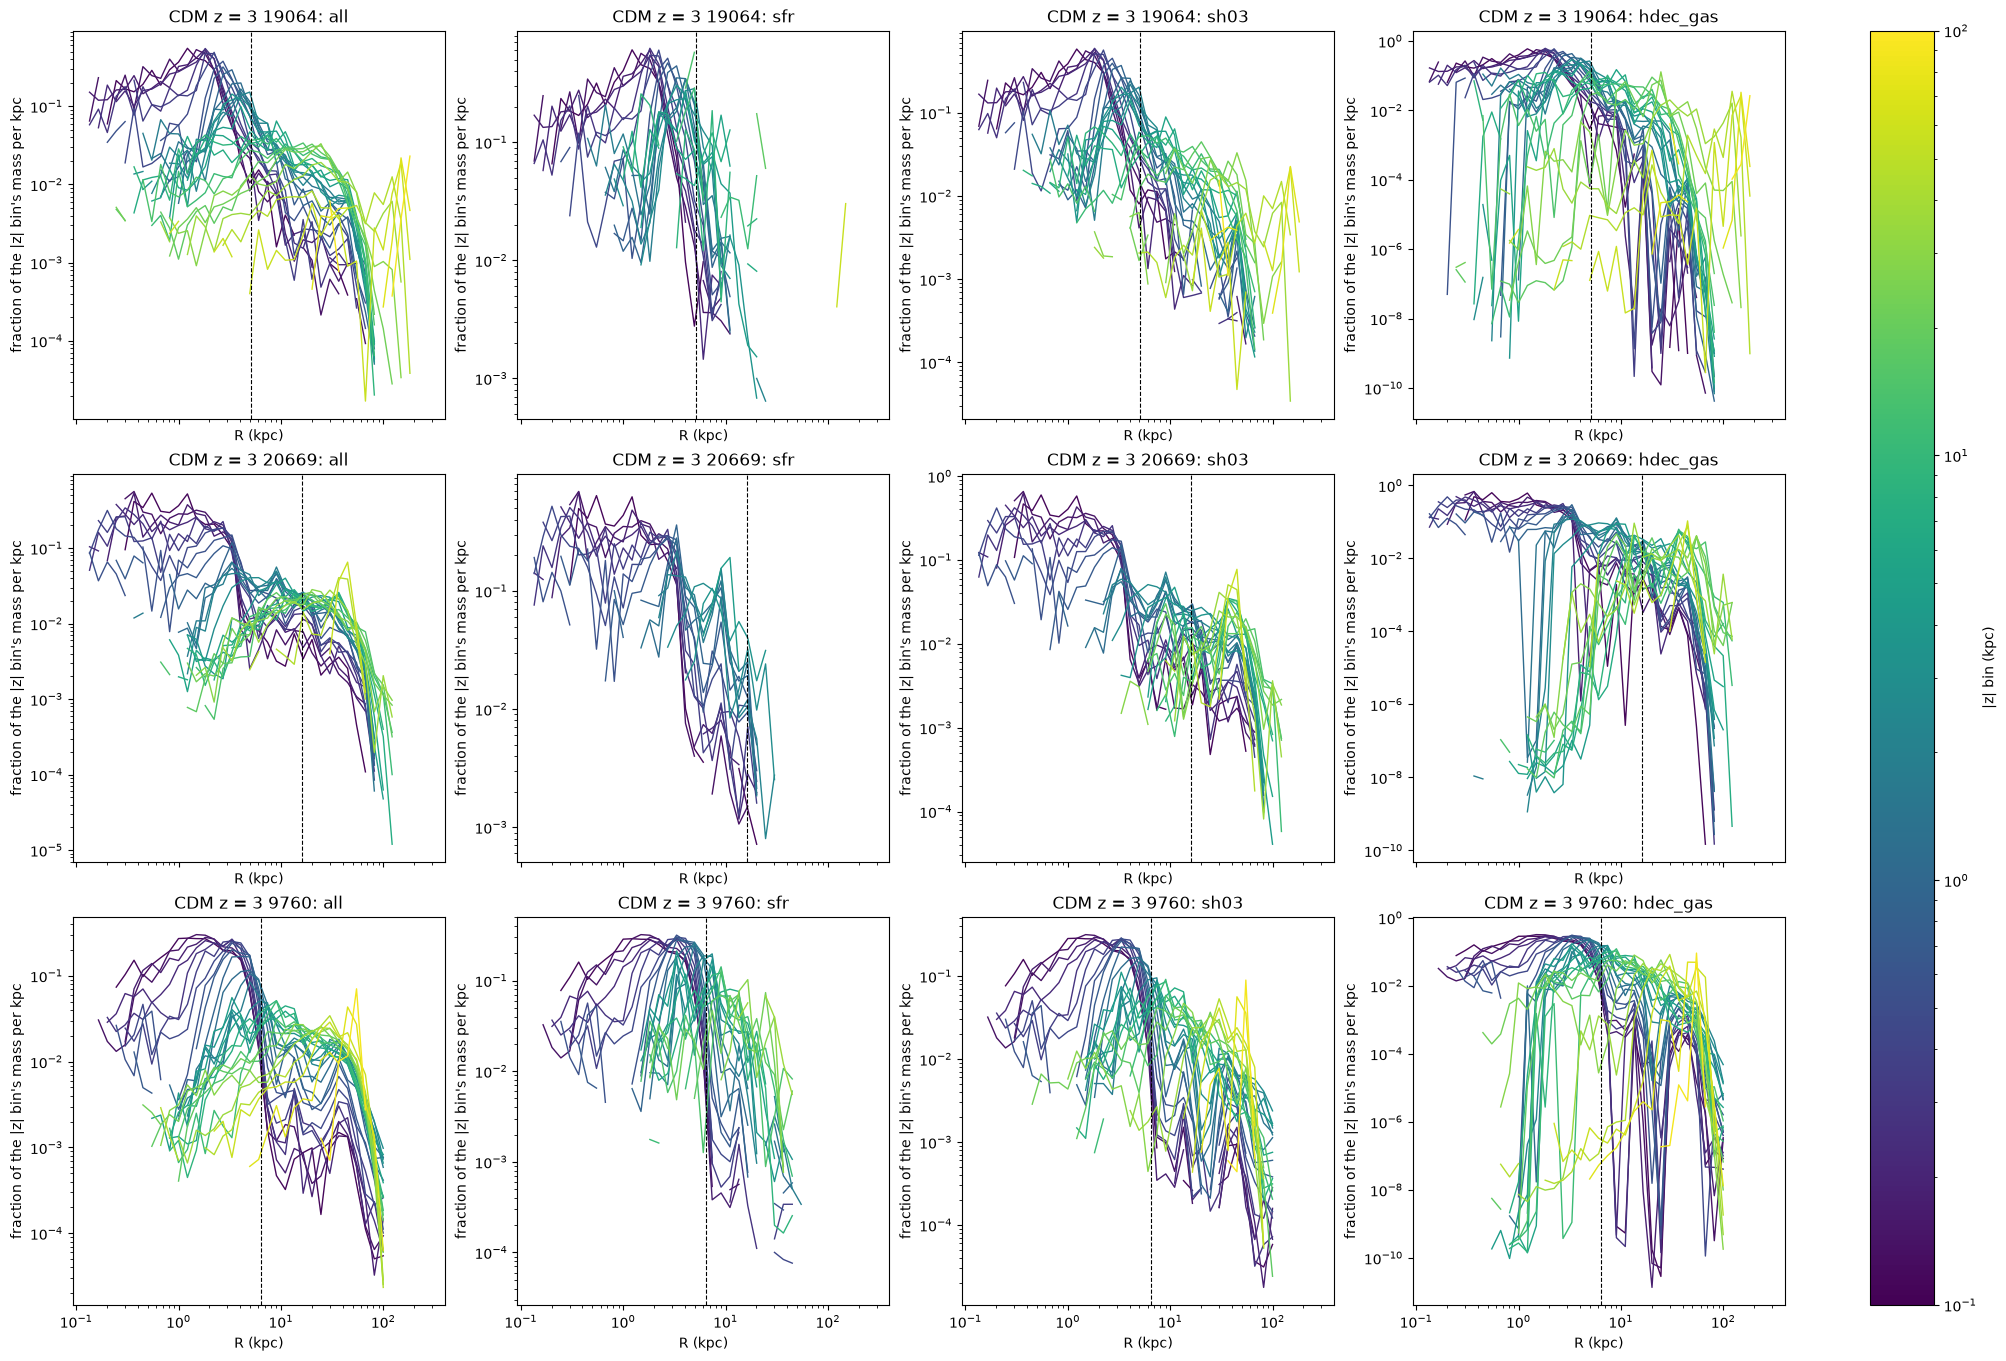

In [10]:
R_edges = edges["R_edges"]
Rc, dR = np.sqrt(R_edges[1:] * R_edges[:-1]), np.diff(R_edges)
znorm = LogNorm(z_bins[0], z_bins[-1])
ylabels = {"cumulative": "mass within R in the |z| bin (Msun)",
           "derivative": "dM/dR in the |z| bin (Msun/kpc)",
           "fraction": "fraction of the |z| bin's mass per kpc"}
for q, ylabel in ylabels.items():
    fig, axes = plt.subplots(len(show), len(defs), figsize=(5 * len(defs), 4.5 * len(show)), sharex=True, constrained_layout=True, squeeze=False)
    for row, (model, z, sub) in zip(axes, show):
        a = data[(model, z)]
        i = np.flatnonzero(a["halo_ids"] == sub)
        if len(i) != 1:
            raise KeyError(f"{model} z{z} {sub} is not in the gas-mass file")
        i = i[0]
        for ax, d in zip(row, defs):
            for j, zj in enumerate(zc):
                m = a[f"map_Rz_{d}"][i][:, zk + j].astype(float)
                if m.sum() == 0:
                    continue
                if q == "cumulative":
                    x, y = R_edges[1:], np.cumsum(m)
                elif q == "derivative":  # first R bin also holds R < 0.1 kpc
                    x, y = Rc[1:], m[1:] / dR[1:]
                else:
                    x, y = Rc[1:], m[1:] / m.sum() / dR[1:]
                ax.plot(x, y, color=plt.cm.viridis(znorm(zj)), lw=1)
            ax.axvline(a["R_rings_kpc"][i], color="k", lw=0.8, ls="--")
            ax.set_xscale("log")
            ax.set_yscale("log", nonpositive="mask")
            ax.set_title(f"{model} z = {z:g} {sub}: {d}")
            ax.set_xlabel("R (kpc)")
            ax.set_ylabel(ylabel)
    fig.colorbar(plt.cm.ScalarMappable(norm=znorm, cmap="viridis"), ax=axes, label="|z| bin (kpc)")
    plt.show()

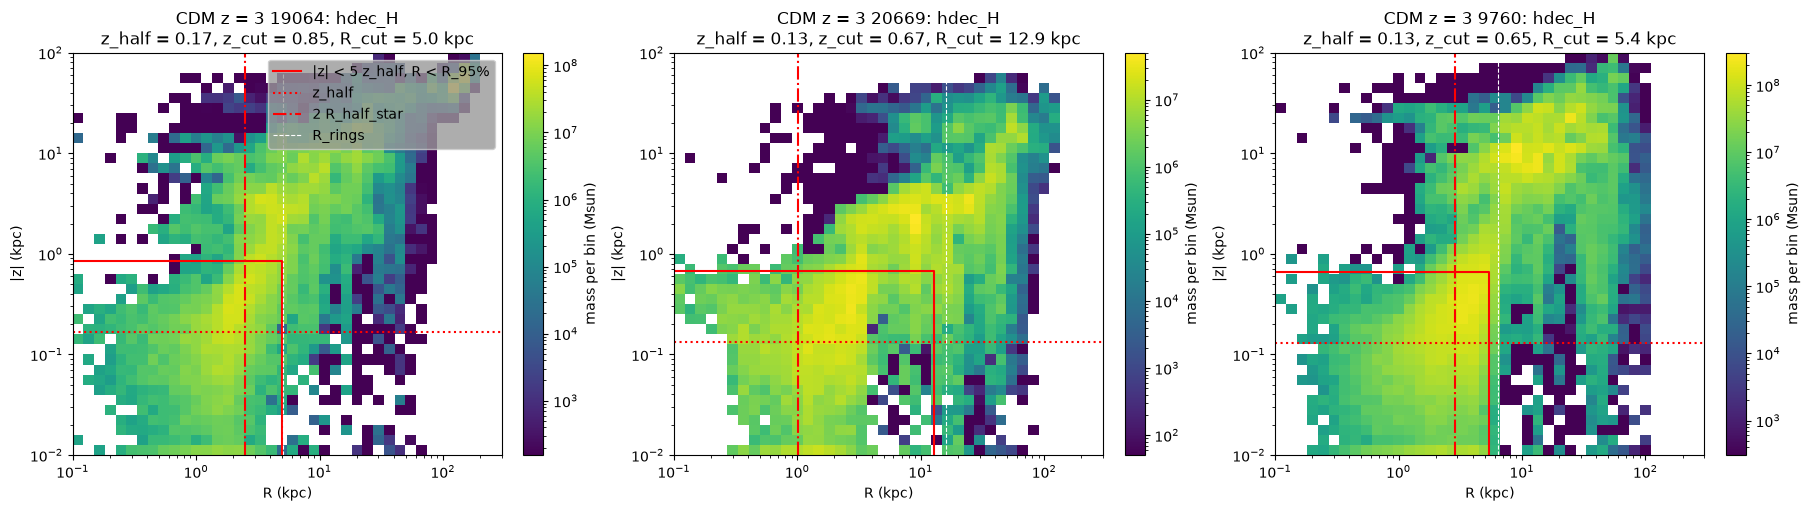

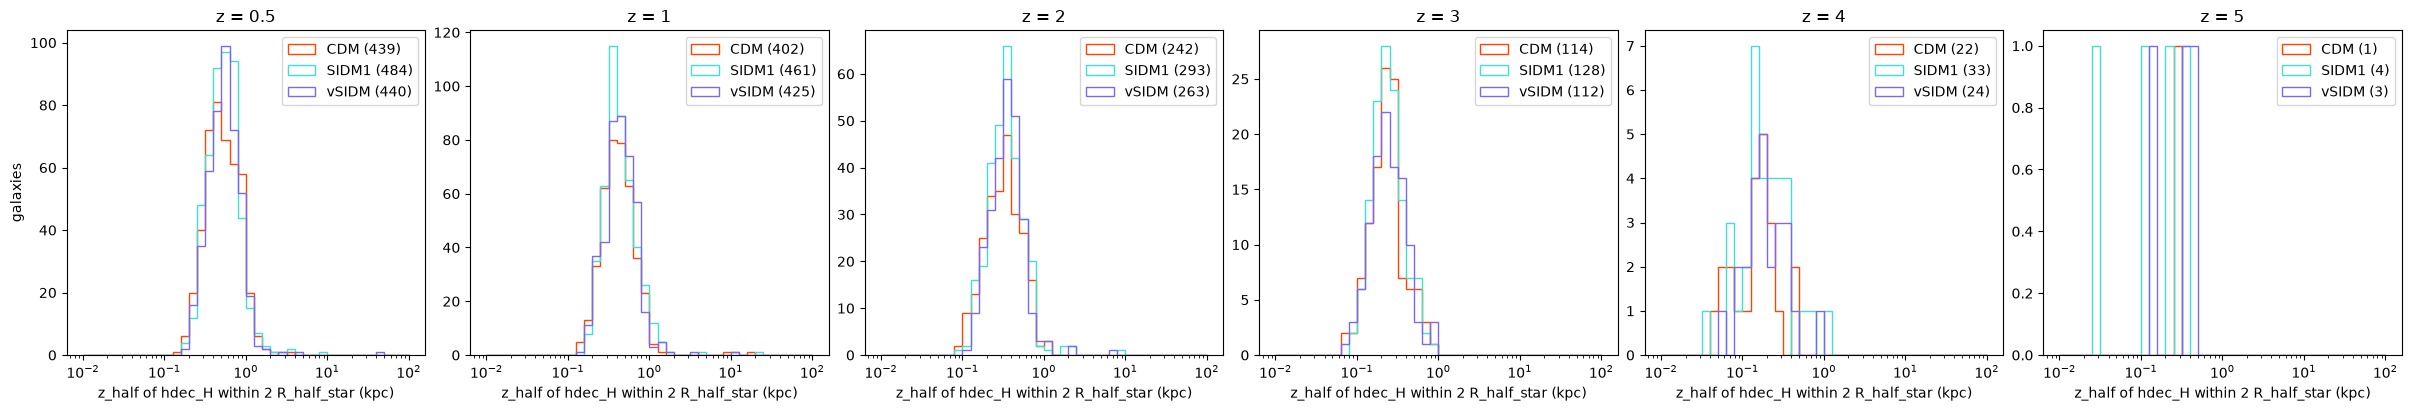

In [13]:
VCIRC = Path(cfg["paths"]["scratch_processed"]) / "vcirc"
k_cut, q_R = 5, 0.95
lR, lz = np.log10(edges["R_edges"]), np.log10(edges["z_edges"])
cut = {}
for model in models:
    for z in redshifts:
        a = data[(model, z)]
        v, _ = load_flat(VCIRC / f"vcirc_{model}_{snap_of[z]:03d}.hdf5")
        r_half = dict(zip(v["halo_ids"], v["R_half_star"]))
        missing = [s for s in a["halo_ids"] if s not in r_half]
        if missing:
            raise KeyError(f"{model} z = {z:g}: no R_half_star for {missing}")
        R2 = 2 * np.array([r_half[s] for s in a["halo_ids"]])
        with np.errstate(invalid="ignore", divide="ignore"):
            wR = np.clip((np.log10(R2)[:, None] - lR[:-1]) / np.diff(lR), 0, 1)  # share of each bin below the cut
            prof_z = (a["map_Rz_hdec_H"] * wR[:, :, None]).sum(axis=1)
            z_half = mass_quantile(prof_z, prof_z.sum(axis=1), edges["z_edges"], 0.5)
            wz = np.clip((np.log10(k_cut * z_half)[:, None] - lz[:-1]) / np.diff(lz), 0, 1)
            prof_R = (a["map_Rz_hdec_H"] * wz[:, None, :]).sum(axis=2)
            R_cut = mass_quantile(prof_R, prof_R.sum(axis=1), edges["R_edges"], q_R)
        bad = np.isnan(z_half)
        if bad.any():
            print(f"{model} z = {z:g}: {bad.sum()} of {len(bad)} galaxies have no hdec_H mass within 2 R_half_star, left out")
        cut[(model, z)] = dict(R2=R2, z_half=z_half, z_cut=k_cut * z_half, R_cut=R_cut)

fig, axes = plt.subplots(1, len(show), figsize=(6 * len(show), 5), constrained_layout=True, squeeze=False)
for ax, (model, z, sub) in zip(axes[0], show):
    a, c = data[(model, z)], cut[(model, z)]
    i = np.flatnonzero(a["halo_ids"] == sub)
    if len(i) != 1:
        raise KeyError(f"{model} z{z} {sub} is not in the gas-mass file")
    i = i[0]
    m = a["map_Rz_hdec_H"][i]
    im = ax.pcolormesh(edges["R_edges"], edges["z_edges"], m.T, norm=LogNorm(vmin=m.max() * 1e-6, vmax=m.max()))
    ax.plot([edges["R_edges"][0], c["R_cut"][i], c["R_cut"][i]], [c["z_cut"][i], c["z_cut"][i], edges["z_edges"][0]],
            color="r", label=f"|z| < {k_cut} z_half, R < R_{q_R:.0%}")
    ax.axhline(c["z_half"][i], color="r", ls=":", label="z_half")
    ax.axvline(c["R2"][i], color="r", ls="-.", label="2 R_half_star")
    ax.axvline(a["R_rings_kpc"][i], color="w", ls="--", lw=0.8, label="R_rings")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"{model} z = {z:g} {sub}: hdec_H\nz_half = {c['z_half'][i]:.2f}, z_cut = {c['z_cut'][i]:.2f}, R_cut = {c['R_cut'][i]:.1f} kpc")
    ax.set_xlabel("R (kpc)")
    ax.set_ylabel("|z| (kpc)")
    fig.colorbar(im, ax=ax, label="mass per bin (Msun)")
axes[0, 0].legend(facecolor="0.6")
plt.show()

fig, axes = plt.subplots(1, len(redshifts), figsize=(4 * len(redshifts), 4), sharex=True, constrained_layout=True)
for ax, z in zip(axes, redshifts):
    for model in models:
        zh = cut[(model, z)]["z_half"]
        zh = zh[np.isfinite(zh)]
        ax.hist(zh, bins=edges["z_edges"], histtype="step", color=colors[model], label=f"{model} ({len(zh)})")
    ax.set_xscale("log")
    ax.set_title(f"z = {z:g}")
    ax.set_xlabel("z_half of hdec_H within 2 R_half_star (kpc)")
    ax.legend()
axes[0].set_ylabel("galaxies")
plt.show()